# 11 – Agent report: overview of the AI-generated datasets
Answers Mohamed's questions for **each dataset**:
1. **Latest date** (latest PR / commit) and first date
2. **Size** (number of PRs, commits or files, and repos)
3. **Contribution of each AI agent** (PRs per agent)
4. **How the agent is involved** (how we know the code is from an AI)
5. **Python** (how many are Python)

| Section | Dataset | 1 row = |
|---|---|---|
| 1 | AIDev v4 (full, read from your PC) | AI PR |
| 2 | AIDev v5 (Hugging Face page only) | AI PR |
| 3 | AIDev-pop (repos > 100 stars) | AI PR |
| 4 | Watanabe 2025 | Claude Code PR |
| 5 | Xia & Miller 2026 | AI commit |
| 6 | Sawada | AI commit |
| 7 | Yu 2024 | file with ChatGPT/Copilot code |
| 8 | Final tables + Excel + charts | |

Output: `tables/datasets_overview.csv`, `tables/per_agent.csv`, `tables/Agent_report.xlsx`, `charts/`.

In [1]:
import sys, os, glob
sys.path.insert(0, "../..")
from common import *
D = os.path.join("..", "..", "..", "data")
rows, per_agent = [], []
def rng(col):
    # first and latest date; ignores empty or bad values
    try:
        dt = pd.to_datetime(col, errors="coerce", utc=True, format="mixed").dropna()
    except (TypeError, ValueError):
        dt = pd.to_datetime(col, errors="coerce", utc=True).dropna()
    return (dt.min(), dt.max()) if len(dt) else ("", "")

def add(name, unit, size, repos, first, last, agents, how, python, separate):
    rows.append(dict(dataset=name, unit=unit, size=size, repos=repos, first_date=str(first)[:10], latest_date=str(last) if "(" in str(last) else str(last)[:10],
                     agents=agents, how_agent_involved=how, python=python, separate_from_AIDev=separate))
    print(f"{name}: {size:,} {unit}s | {rows[-1]['first_date']} -> {rows[-1]['latest_date']} | Python: {python}")
def agents_of(name, counts):
    show_numbers(pd.Series(counts), name + ' - per agent')
    counts = counts.rename(agent_of) if name == "Sawada" else counts
    for a, n in counts.items(): per_agent.append(dict(dataset=name, agent=a, count=int(n)))

## 1. AIDev v4 (full, 2.7M PRs) – read from your PC
Set `RAW` to the folder with `all_pull_request.parquet` and `all_repository.parquet`.

In [2]:
RAW = r"C:\Users\GIGABYTE\Desktop\code_theis\evolution-assurance\data\raw"   # <- change if needed
f = os.path.join(RAW, "all_pull_request.parquet")
if os.path.exists(f):
    v4 = pd.read_parquet(f, columns=["id", "agent", "created_at", "repo_url"])
    v4["agent"] = v4["agent"].map(agent_of)
    rf = os.path.join(RAW, "all_repository.parquet")
    py = "repository file missing"
    if os.path.exists(rf):
        rp = pd.read_parquet(rf)
        key = "url" if "url" in rp else rp.columns[0]
        v4 = v4.merge(rp[[key, "language"]].rename(columns={key: "repo_url"}), on="repo_url", how="left")
        v4["is_python"] = v4["language"].eq("Python")
        py = f"{int(v4.is_python.sum()):,} PRs"
    add("AIDev v4 (official)", "PR", len(v4), v4.repo_url.nunique(), *rng(v4.created_at),
        v4.agent.nunique(), "Agent opened the PR", py, "main source")
    agents_of("AIDev v4", v4.agent.value_counts())
    if "is_python" in v4:
        agents_of("AIDev v4 – Python", v4[v4.is_python].agent.value_counts())
else:
    print("AIDev v4 not found – set RAW. Using the numbers from the Hugging Face page.")
    add("AIDev v4 (official)", "PR", 2743854, 327477, "", "2025-10 (cutoff Nov 2025)", 6, "Agent opened the PR", "run with RAW set", "main source")
    agents_of("AIDev v4", pd.Series({"Codex": 2069595, "Copilot": 349695, "Cursor": 212544, "Jules": 50490, "Devin": 43298, "Claude Code": 18232}))

AIDev v4 not found – set RAW. Using the numbers from the Hugging Face page.
AIDev v4 (official): 2,743,854 PRs |  -> 2025-10 (cutoff Nov 2025) | Python: run with RAW set


*Exact numbers – AIDev v4 - per agent*

,number,%
Codex,2069595.0,75.4
Copilot,349695.0,12.7
Cursor,212544.0,7.7
Jules,50490.0,1.8
Devin,43298.0,1.6
Claude Code,18232.0,0.7
TOTAL,2743854.0,100.0


## 2. AIDev v5 (work in progress) – from the Hugging Face page only

In [3]:
add("AIDev v5 (work in progress)", "PR", 7600000, "", "", "2026-03-31", "not checked", "Agent opened the PR", "not checked", "newer AIDev")

AIDev v5 (work in progress): 7,600,000 PRs |  -> 2026-03-31 | Python: not checked


## 3. AIDev-pop (repos > 100 stars) + task type

In [4]:
ai = pd.read_csv(os.path.join(D, "AI_PRS_DATASET", "AI_PRS_DATASET.csv"), low_memory=False)
pop = ai[ai.source == "AIDev-pop"]
add("AIDev-pop", "PR", len(pop), pop.repo.nunique(), *rng(pop.created_at), pop.agent.nunique(),
    "Agent opened the PR; + task type (fix, feature…)", f"{int(pop.is_python.sum()):,} PRs", "No (inside AIDev)")
agents_of("AIDev-pop", pop.agent.value_counts())
agents_of("AIDev-pop – Python", pop[pop.is_python == True].agent.value_counts())

AIDev-pop: 33,596 PRs | 2024-12-24 -> 2025-07-30 | Python: 7,191 PRs


*Exact numbers – AIDev-pop - per agent*

,number,%
agent,,
Codex,21799.0,64.9
Copilot,4970.0,14.8
Devin,4827.0,14.4
Cursor,1541.0,4.6
Claude Code,459.0,1.4
TOTAL,33596.0,100.0


*Exact numbers – AIDev-pop – Python - per agent*

,number,%
agent,,
Codex,5209.0,72.4
Devin,1069.0,14.9
Copilot,559.0,7.8
Cursor,254.0,3.5
Claude Code,100.0,1.4
TOTAL,7191.0,100.0


## 4. Watanabe 2025 – Claude Code PRs

In [5]:
W = os.path.join(D, "04_Watanabe_ClaudeCode", "ontheuseofagenticcoding", "Data")
w = pd.concat([pd.read_csv(os.path.join(W, f"APR-{x}.csv")) for x in ["MERGED", "OPEN", "CLOSED"]])
add("Watanabe 2025", "PR", len(w), (w.owner + "/" + w.repo_name).nunique(), *rng(w.created_at), 1,
    'PR text says "Generated with Claude Code"', "not given", "Yes (756 not in AIDev-pop)")
agents_of("Watanabe", pd.Series({"Claude Code": len(w)}))

Watanabe 2025: 797 PRs | 2025-02-21 -> 2025-04-30 | Python: not given


*Exact numbers – Watanabe - per agent*

,number,%
Claude Code,797.0,100.0
TOTAL,797.0,100.0


## 5. Xia & Miller 2026 – AI co-authored commits

In [6]:
x = pd.read_csv(os.path.join(D, "02_XiaMiller_PostMerge", "post-merge-reality", "dev", "analysis",
                             "output_rq1b_explore", "rq1b_origin_commit_terminal_maintenance_summary.csv.gz"))
xa = x[x.origin_role == "AI"]
add("Xia & Miller 2026", "Commit", len(xa), xa.repo.nunique(), *rng(xa.origin_commit_date), 7, 'AI is co-author of the commit ("Co-authored-by: Claude…")', "not given", "Yes")
e = pd.read_csv(os.path.join(D, "ENRICH", "FINAL_AI_FIXES_ENRICHED.csv"), low_memory=False)
agents_of("Xia & Miller (fixed AI commits)", e[e.paper.str.startswith("Xia")].agent.value_counts())

Xia & Miller 2026: 29,100 Commits | 2025-05-01 -> 2026-05-31 | Python: not given


*Exact numbers – Xia & Miller (fixed AI commits) - per agent*

,number,%
agent,,
Claude Code,4980.0,63.7
Copilot,2256.0,28.8
Cursor,229.0,2.9
Devin,175.0,2.2
Jules,77.0,1.0
Gemini,49.0,0.6
Codex,44.0,0.6
AI (not recognised),12.0,0.2
TOTAL,7822.0,100.0


## 6. Sawada – AI commits

In [7]:
s = pd.read_csv(os.path.join(D, "03_Sawada", "ai-code-maintainability", "dataset", "analyze-dataset", "dataset_AI_commits.csv"))
sa = s[s.is_ai == "AI"]
add("Sawada", "Commit", len(sa), sa.repository.nunique(), *rng(sa.commit_date), sa.ai_tool.nunique(),
    "Commit authored/co-authored by an AI tool", "not given", "Yes")
agents_of("Sawada", sa.ai_tool.value_counts())

Sawada: 328 Commits | 2025-01-24 -> 2025-08-17 | Python: not given


*Exact numbers – Sawada - per agent*

,number,%
ai_tool,,
GitHub Copilot,169.0,51.5
Devin,144.0,43.9
Cursor,12.0,3.7
Claude,3.0,0.9
TOTAL,328.0,100.0


## 7. Yu 2024 – files with ChatGPT/Copilot code

In [8]:
yf = glob.glob(os.path.join(D, "05_Yu_ChatGPT_Copilot", "wherecodegenerationbyllm", "results-code-change-type", "*.xlsx"))
y = pd.concat([pd.read_excel(f, sheet_name=0).assign(file_language=os.path.basename(f).split("-")[0]) for f in yf])
add("Yu 2024", "File", len(y), y.project_name.nunique(), *rng(y.create_time), 2,
    'Code comment "generated by ChatGPT/Copilot"', f"{int((y.file_language == 'python').sum())} files", "Yes")
show_numbers(y.file_language.value_counts(), "Yu – files per language")

Yu 2024: 1,413 Files | 2023-02-01 -> 2024-05-14 | Python: 660 files


*Exact numbers – Yu – files per language*

,number,%
file_language,,
python,660.0,46.7
javascript,349.0,24.7
java,174.0,12.3
cpp,151.0,10.7
typescript,79.0,5.6
TOTAL,1413.0,100.0


,number,%
file_language,,
python,660.0,46.7
javascript,349.0,24.7
java,174.0,12.3
cpp,151.0,10.7
typescript,79.0,5.6
TOTAL,1413.0,100.0


## 8. Final tables
### 8.1 Datasets overview (date, size, agents, Python)

In [9]:
ov = save_table(pd.DataFrame(rows), "datasets_overview")
pa = save_table(pd.DataFrame(per_agent), "per_agent")
display(ov.drop(columns=["how_agent_involved"]))

,dataset,unit,size,repos,first_date,latest_date,agents,python,separate_from_AIDev
0,AIDev v4 (official),PR,2743854,327477,,2025-10 (cutoff Nov 2025),6,run with RAW set,main source
1,AIDev v5 (work in progress),PR,7600000,,,2026-03-31,not checked,not checked,newer AIDev
2,AIDev-pop,PR,33596,2807,2024-12-24,2025-07-30,5,"7,191 PRs",No (inside AIDev)
3,Watanabe 2025,PR,797,240,2025-02-21,2025-04-30,1,not given,Yes (756 not in AIDev-pop)
4,Xia & Miller 2026,Commit,29100,182,2025-05-01,2026-05-31,7,not given,Yes
5,Sawada,Commit,328,32,2025-01-24,2025-08-17,4,not given,Yes
6,Yu 2024,File,1413,977,2023-02-01,2024-05-14,2,660 files,Yes


### 8.2 How the agent is involved in each dataset

In [10]:
display(ov[["dataset", "unit", "how_agent_involved", "separate_from_AIDev"]])

,dataset,unit,how_agent_involved,separate_from_AIDev
0,AIDev v4 (official),PR,Agent opened the PR,main source
1,AIDev v5 (work in progress),PR,Agent opened the PR,newer AIDev
2,AIDev-pop,PR,"Agent opened the PR; + task type (fix, feature…)",No (inside AIDev)
3,Watanabe 2025,PR,"PR text says ""Generated with Claude Code""",Yes (756 not in AIDev-pop)
4,Xia & Miller 2026,Commit,"AI is co-author of the commit (""Co-authored-by: Claude…"")",Yes
5,Sawada,Commit,Commit authored/co-authored by an AI tool,Yes
6,Yu 2024,File,"Code comment ""generated by ChatGPT/Copilot""",Yes


### 8.3 Contribution of each AI agent (PRs / commits per agent)

In [11]:
per = pa.pivot_table(index="agent", columns="dataset", values="count", aggfunc="sum").fillna(0).astype(int)
display(per)

dataset,AIDev v4,AIDev-pop,AIDev-pop – Python,Sawada,Watanabe,Xia & Miller (fixed AI commits)
agent,,,,,,
AI (not recognised),0,0,0,0,0,12
Claude Code,18232,459,100,3,797,4980
Codex,2069595,21799,5209,0,0,44
Copilot,349695,4970,559,169,0,2256
Cursor,212544,1541,254,12,0,229
Devin,43298,4827,1069,144,0,175
Gemini,0,0,0,0,0,49
Jules,50490,0,0,0,0,77


### 8.4 Save everything in one Excel file

In [12]:
with pd.ExcelWriter(os.path.join("tables", "Agent_report.xlsx")) as xw:
    ov.to_excel(xw, sheet_name="Overview", index=False)
    per.to_excel(xw, sheet_name="Per agent")
    pa.to_excel(xw, sheet_name="Per agent (long)", index=False)
print("Saved tables/Agent_report.xlsx")

Saved tables/Agent_report.xlsx


### 8.5 Charts

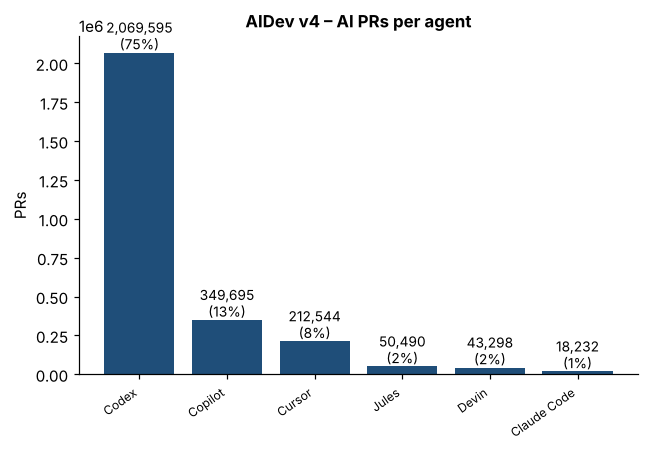

*Exact numbers – AIDev v4 – AI PRs per agent*

,number,%
agent,,
Codex,2069595.0,75.4
Copilot,349695.0,12.7
Cursor,212544.0,7.7
Jules,50490.0,1.8
Devin,43298.0,1.6
Claude Code,18232.0,0.7
TOTAL,2743854.0,100.0


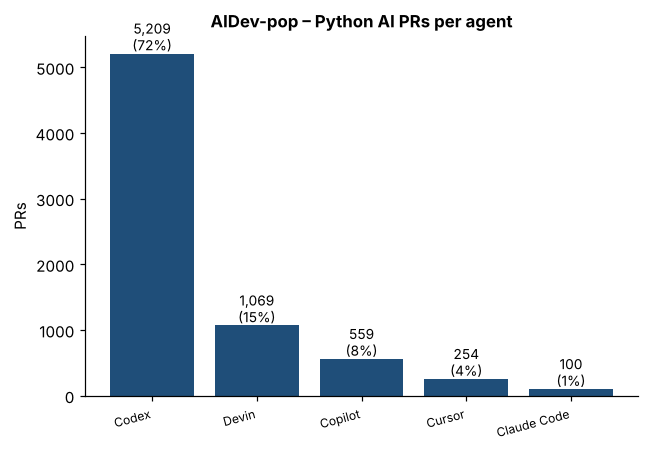

*Exact numbers – AIDev-pop – Python AI PRs per agent*

,number,%
agent,,
Codex,5209.0,72.4
Devin,1069.0,14.9
Copilot,559.0,7.8
Cursor,254.0,3.5
Claude Code,100.0,1.4
TOTAL,7191.0,100.0


In [13]:
big = pa[pa.dataset == "AIDev v4"].set_index("agent")["count"].sort_values(ascending=False)
bar(big, "AIDev v4 – AI PRs per agent", "1_aidev_v4_per_agent.png", "PRs", pct=True)
p = pa[pa.dataset == "AIDev-pop – Python"].set_index("agent")["count"].sort_values(ascending=False)
bar(p, "AIDev-pop – Python AI PRs per agent", "2_aidev_pop_python_per_agent.png", "PRs", pct=True)